# Personalised Air Quality Prediction & Health Advisory
**Google Colab starter notebook — aligned with your project report**

This notebook is a reusable implementation template. Your report does **not** yet specify a final dataset, publisher, target column, geographical coverage, or forecast horizon. Therefore, this notebook asks you to upload your own documented CSV and configure its column names. It does not invent a dataset or performance results.

**Important:** With simultaneous pollutant/weather measurements, this notebook performs a same-time regression estimate. It is not a future forecast unless you create lagged features and define a forecast horizon without using future information.

## 1. Install/import libraries
Colab already includes most of these libraries. Run this cell first.

In [1]:
!pip -q install scikit-learn pandas numpy matplotlib seaborn joblib

import os
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from google.colab import files
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Upload your dataset (CSV)
Before uploading, make sure you know the dataset's publisher/source, licence, location coverage, observation period, sampling frequency and units. Record these in your report.

In [2]:
uploaded = files.upload()  # Choose your .csv file from your Mac

csv_files = [name for name in uploaded if name.lower().endswith(".csv")]
if not csv_files:
    raise ValueError("Please upload a CSV file.")

CSV_PATH = csv_files[0]
df = pd.read_csv(CSV_PATH)

print("Loaded:", CSV_PATH)
print("Shape:", df.shape)
display(df.head())
print("\\nColumn names:")
print(df.columns.tolist())

Saving city_day.csv to city_day.csv
Loaded: city_day.csv
Shape: (29531, 16)


,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket
0,Ahmedabad,2015-01-01,NaN,NaN,0.92,18.22,17.15,NaN,0.92,27.64,133.36,0.00,0.02,0.00,NaN,NaN
1,Ahmedabad,2015-01-02,NaN,NaN,0.97,15.69,16.46,NaN,0.97,24.55,34.06,3.68,5.50,3.77,NaN,NaN
2,Ahmedabad,2015-01-03,NaN,NaN,17.40,19.30,29.70,NaN,17.40,29.07,30.70,6.80,16.40,2.25,NaN,NaN
3,Ahmedabad,2015-01-04,NaN,NaN,1.70,18.48,17.97,NaN,1.70,18.59,36.08,4.43,10.14,1.00,NaN,NaN
4,Ahmedabad,2015-01-05,NaN,NaN,22.10,21.42,37.76,NaN,22.10,39.33,39.31,7.01,18.89,2.78,NaN,NaN


\nColumn names:
['City', 'Date', 'PM2.5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3', 'CO', 'SO2', 'O3', 'Benzene', 'Toluene', 'Xylene', 'AQI', 'AQI_Bucket']


## 3. Configure the dataset
Edit the values below to match your CSV exactly.

- `TARGET_COL`: choose **one** numeric target, either an existing AQI column or PM2.5 concentration.
- `DATETIME_COL`: set to your timestamp column, or `None` if there is no timestamp.
- `DROP_COLS`: remove IDs, text descriptions, or columns that would reveal the target.
- Do not include future measurements as predictors. If AQI is calculated from pollutant concentrations, check for target leakage before using those pollutants as inputs.

In [12]:
# EDIT THESE SETTINGS AFTER CHECKING df.columns ABOVE
TARGET_COL = "AQI"       # Example only: change to your actual target column
DATETIME_COL = "Date"    # Example only: change to your timestamp column, or use None
DROP_COLS = ["AQI_Bucket"]           # Example: ["Record_ID", "City_Name"] if unsuitable

# If the actual column names are "PM2.5", "timestamp", etc.,
# write those exact names including punctuation and capitalisation.

if TARGET_COL not in df.columns:
    raise ValueError(f"TARGET_COL '{TARGET_COL}' not found. Available columns: {df.columns.tolist()}")

if DATETIME_COL is not None and DATETIME_COL not in df.columns:
    raise ValueError(f"DATETIME_COL '{DATETIME_COL}' not found. Set it to the exact timestamp column or None.")

print("Target:", TARGET_COL)
print("Timestamp:", DATETIME_COL)
print("Dataset columns:", df.columns.tolist())

Target: AQI
Timestamp: Date
Dataset columns: ['City', 'Date', 'PM2.5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3', 'CO', 'SO2', 'O3', 'Benzene', 'Toluene', 'Xylene', 'AQI', 'AQI_Bucket']


## 4. Inspect and clean the data
This cell reports missing values, duplicate rows, data types and summary statistics. It removes exact duplicate rows and records with a missing target. It does not automatically delete extreme pollution observations, because they may be genuine events.

In [4]:
print("Data types:")
display(df.dtypes.to_frame("data_type"))

print("Missing values:")
display(df.isna().sum().sort_values(ascending=False).to_frame("missing_count"))

print("Exact duplicate rows:", df.duplicated().sum())
print("Target summary:")
display(df[TARGET_COL].describe())

df = df.drop_duplicates().copy()
df[TARGET_COL] = pd.to_numeric(df[TARGET_COL], errors="coerce")
df = df.dropna(subset=[TARGET_COL]).copy()

if DATETIME_COL is not None:
    df[DATETIME_COL] = pd.to_datetime(df[DATETIME_COL], errors="coerce")
    df = df.dropna(subset=[DATETIME_COL]).sort_values(DATETIME_COL).reset_index(drop=True)

print("Shape after basic cleaning:", df.shape)

Data types:


,data_type
City,object
Date,object
PM2.5,float64
PM10,float64
NO,float64
NO2,float64
NOx,float64
NH3,float64
CO,float64
SO2,float64


Missing values:


,missing_count
Xylene,18109
PM10,11140
NH3,10328
Toluene,8041
Benzene,5623
AQI,4681
AQI_Bucket,4681
PM2.5,4598
NOx,4185
O3,4022


Exact duplicate rows: 0
Target summary:


,AQI
count,24850.000000
mean,166.463581
std,140.696585
min,13.000000
25%,81.000000
50%,118.000000
75%,208.000000
max,2049.000000


Shape after basic cleaning: (24850, 16)


## 5. Exploratory Data Analysis (EDA)
Use these plots to inspect the target distribution and numeric feature relationships. Correlation shows association, not causation.

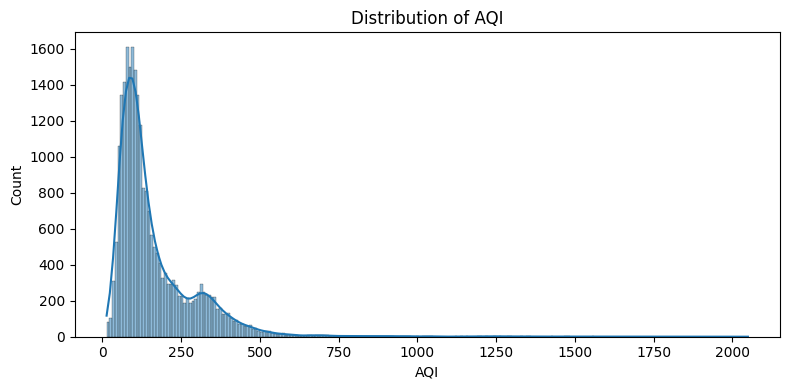

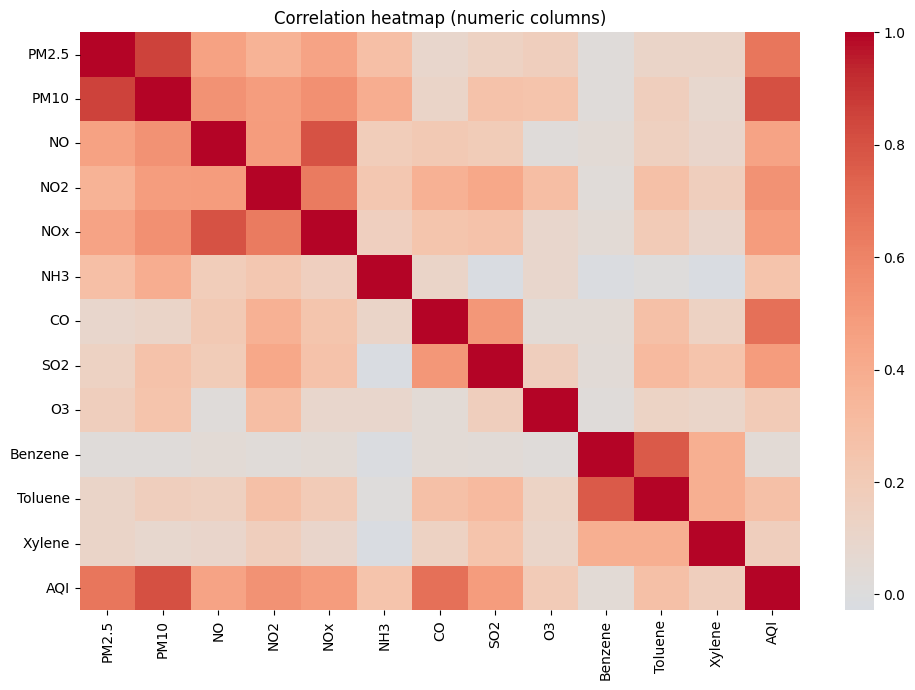

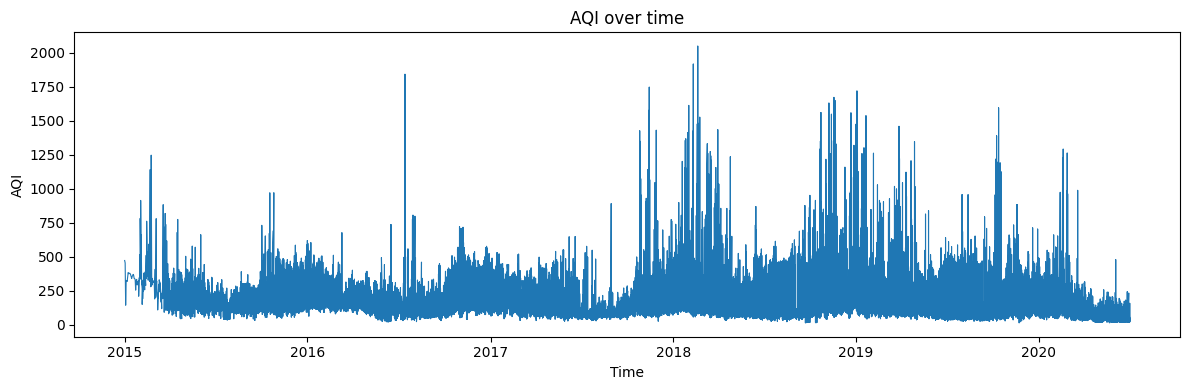

In [5]:
plt.figure(figsize=(8, 4))
sns.histplot(df[TARGET_COL], kde=True)
plt.title(f"Distribution of {TARGET_COL}")
plt.xlabel(TARGET_COL)
plt.tight_layout()
plt.show()

numeric_for_corr = df.select_dtypes(include=np.number)
if numeric_for_corr.shape[1] >= 2:
    plt.figure(figsize=(10, 7))
    sns.heatmap(numeric_for_corr.corr(), cmap="coolwarm", center=0)
    plt.title("Correlation heatmap (numeric columns)")
    plt.tight_layout()
    plt.show()

if DATETIME_COL is not None:
    plt.figure(figsize=(12, 4))
    plt.plot(df[DATETIME_COL], df[TARGET_COL], linewidth=0.8)
    plt.title(f"{TARGET_COL} over time")
    plt.xlabel("Time")
    plt.ylabel(TARGET_COL)
    plt.tight_layout()
    plt.show()

## 6. Prepare features and chronological train/test split
The last 20% of observations are held out for testing. This is preferable for time-dependent data to a random split. If no timestamp exists, the notebook preserves the current row order, but you must verify that the rows are already ordered meaningfully.

Date/time features are derived from the timestamp. The original timestamp is then removed. The target column and explicitly excluded columns are not used as predictors.

In [6]:
work = df.copy()

if DATETIME_COL is not None:
    work["hour"] = work[DATETIME_COL].dt.hour
    work["day_of_week"] = work[DATETIME_COL].dt.dayofweek
    work["month"] = work[DATETIME_COL].dt.month
    work["day_of_year"] = work[DATETIME_COL].dt.dayofyear

drop_now = [TARGET_COL] + DROP_COLS
if DATETIME_COL is not None:
    drop_now.append(DATETIME_COL)

X = work.drop(columns=[c for c in drop_now if c in work.columns])
y = work[TARGET_COL].astype(float)

# Keep only columns with at least one non-missing value
X = X.dropna(axis=1, how="all")

# Convert columns that are numeric-looking but stored as text only if safe
for col in X.columns:
    if X[col].dtype == "object":
        converted = pd.to_numeric(X[col], errors="coerce")
        if converted.notna().mean() >= 0.90:
            X[col] = converted

# Chronological / row-order split: first 80% train, last 20% test
split_index = int(len(X) * 0.80)
if split_index < 2 or len(X) - split_index < 1:
    raise ValueError("Not enough rows for an 80/20 train-test split.")

X_train, X_test = X.iloc[:split_index].copy(), X.iloc[split_index:].copy()
y_train, y_test = y.iloc[:split_index].copy(), y.iloc[split_index:].copy()

numeric_features = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_features = X_train.select_dtypes(exclude=np.number).columns.tolist()

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)

if len(numeric_features) + len(categorical_features) == 0:
    raise ValueError("No usable predictor columns remain. Check DROP_COLS and your dataset.")

Training rows: 19880
Testing rows: 4970
Numeric features: ['PM2.5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3', 'CO', 'SO2', 'O3', 'Benzene', 'Toluene', 'Xylene', 'hour', 'day_of_week', 'month', 'day_of_year']
Categorical features: ['City', 'AQI_Bucket']


## 7. Preprocessing pipeline and train three regression models
Missing numerical values are imputed with the training-set median. Categorical values are imputed with the most frequent training value and one-hot encoded. Preprocessing is fitted inside each model pipeline using training data only.

In [7]:
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(random_state=42, max_depth=10),
    "Random Forest": RandomForestRegressor(
        n_estimators=200, random_state=42, n_jobs=-1, min_samples_leaf=2
    )
}

trained_models = {}
predictions = {}
results = []

for name, estimator in models.items():
    pipe = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", estimator)
    ])
    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_test)

    trained_models[name] = pipe
    predictions[name] = y_pred

    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred) if len(y_test) >= 2 else np.nan

    results.append({
        "Model": name, "MAE": mae, "MSE": mse, "RMSE": rmse, "R2": r2
    })

results_df = pd.DataFrame(results).sort_values("RMSE")
display(results_df.round(4))

,Model,MAE,MSE,RMSE,R2
2,Random Forest,11.2227,350.8197,18.7302,0.9567
1,Decision Tree,12.5178,507.7776,22.5339,0.9373
0,Linear Regression,14.7649,539.5801,23.2289,0.9334


## 8. Compare model performance
Lower MAE, MSE and RMSE are preferred. Higher R² is generally preferred, but interpret it together with error metrics and the test-set design. The model with the lowest test RMSE is selected here as a simple comparison rule; review all metrics before making a final choice.

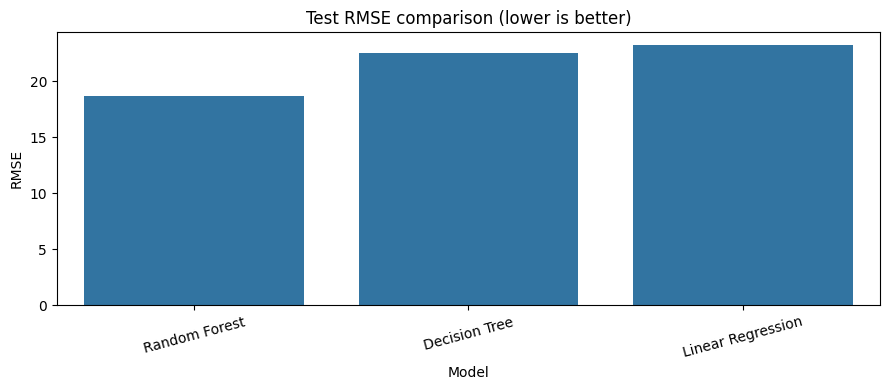

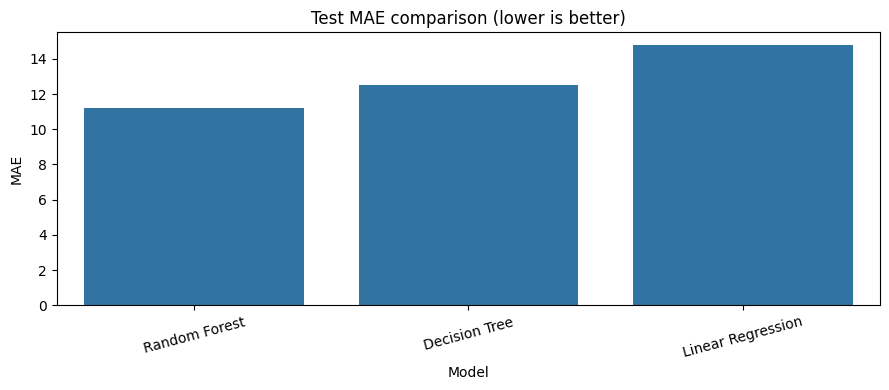

Lowest test RMSE in this run: Random Forest
This is a measured result for your uploaded dataset and this split; do not copy example numbers from elsewhere.


In [9]:
plt.figure(figsize=(9, 4))
sns.barplot(data=results_df, x="Model", y="RMSE")
plt.title("Test RMSE comparison (lower is better)")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 4))
sns.barplot(data=results_df, x="Model", y="MAE")
plt.title("Test MAE comparison (lower is better)")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

best_model_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_model_name]
best_predictions = predictions[best_model_name]

print("Lowest test RMSE in this run:", best_model_name)
print("This is a measured result for your uploaded dataset and this split; do not copy example numbers from elsewhere.")

## 9. Actual vs predicted and residual plots
These plots help inspect prediction errors. Save the plots/results for your experimental-results chapter.

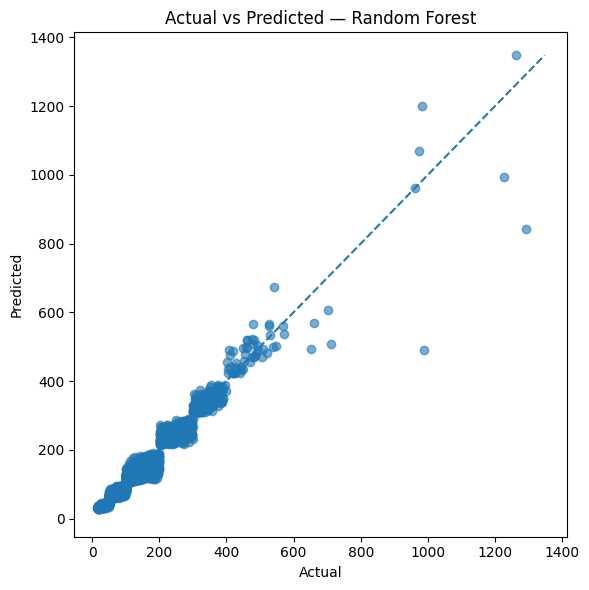

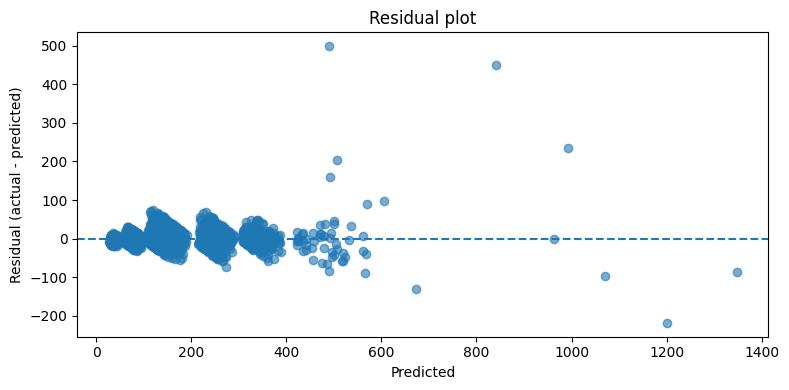

In [10]:
plt.figure(figsize=(6, 6))
plt.scatter(y_test, best_predictions, alpha=0.6)
low = min(float(y_test.min()), float(np.min(best_predictions)))
high = max(float(y_test.max()), float(np.max(best_predictions)))
plt.plot([low, high], [low, high], linestyle="--")
plt.xlabel("Actual")
plt.ylabel("Predicted")
plt.title(f"Actual vs Predicted — {best_model_name}")
plt.tight_layout()
plt.show()

residuals = y_test.to_numpy() - best_predictions
plt.figure(figsize=(8, 4))
plt.scatter(best_predictions, residuals, alpha=0.6)
plt.axhline(0, linestyle="--")
plt.xlabel("Predicted")
plt.ylabel("Residual (actual - predicted)")
plt.title("Residual plot")
plt.tight_layout()
plt.show()

## 10. Personalised advisory rule demonstration
The regression model predicts a numerical AQI or PM2.5 value. A separate rule-based layer turns an **officially determined category** plus the user's activity and optional sensitivity preference into general guidance.

Do not invent AQI category cut-offs. First choose and cite the applicable official standard (for example, CPCB's Indian AQI resources) and implement its exact category thresholds. For now, enter the category manually to test the advisory wording.

In [11]:
def make_advisory(category, activity, sensitivity="General"):
    category = str(category).strip().lower()
    activity = str(activity).strip().lower()
    sensitivity = str(sensitivity).strip().lower()

    if category in {"good", "satisfactory", "low"}:
        message = "Air quality is comparatively better under the selected category. Check the latest local update before going outdoors."
    elif category in {"moderate"}:
        message = "Consider general caution and monitor local air-quality updates, especially during prolonged outdoor activity."
    elif category in {"poor", "very poor", "severe"}:
        message = "Consider limiting prolonged or strenuous outdoor activity and checking whether a cleaner period or indoor alternative is available."
    else:
        message = "Category not recognised. Check the selected official AQI standard and category label."

    if activity in {"jogging", "running", "cycling"} and category in {"poor", "very poor", "severe"}:
        message += " For strenuous activity such as jogging, running or cycling, consider reducing intensity or choosing an indoor alternative."
    elif activity == "walking" and category in {"poor", "very poor", "severe"}:
        message += " Consider shortening the walk or moving it to a cleaner period."

    if sensitivity in {"higher", "sensitive", "high"}:
        message += " You selected a higher-sensitivity preference, so consider taking a more cautious approach."

    return message + " This is general environmental information, not medical advice."

# Example only: replace with a category determined using your selected official standard
print(make_advisory(
    category="Poor",
    activity="Jogging",
    sensitivity="Medium"
))

Consider limiting prolonged or strenuous outdoor activity and checking whether a cleaner period or indoor alternative is available. For strenuous activity such as jogging, running or cycling, consider reducing intensity or choosing an indoor alternative. This is general environmental information, not medical advice.


## 11. Save your model and results
The saved model is specific to the dataset and feature columns used in this run. Keep the dataset source and configuration with it.

In [ ]:
joblib.dump(best_model, "best_air_quality_model.joblib")
results_df.to_csv("model_evaluation_results.csv", index=False)

print("Saved best_air_quality_model.joblib")
print("Saved model_evaluation_results.csv")

files.download("model_evaluation_results.csv")
files.download("best_air_quality_model.joblib")

## 12. What you must fill into your report
After running the notebook, record:
1. Exact dataset name, publisher, URL, access date and licence.
2. Geographic coverage, observation period and sampling frequency.
3. Number of rows before and after cleaning.
4. Missing-value and duplicate counts and the actions taken.
5. Exact target variable (AQI or PM2.5), units and final input features.
6. Test-set MAE, MSE, RMSE and R² for all three models.
7. Plots: target distribution, correlation heatmap (if appropriate), actual-vs-predicted, residual plot and model comparison.
8. Whether the task is same-time estimation or genuine future forecasting.

**Do not describe same-time estimation as future forecasting.** For future forecasting, build lagged/time-based features and validate chronologically so that no future information enters training features. Also verify that predictor variables would actually be available at the time a forecast is made.